C:\Users\Wahaj Raza\AppData\Local\Temp\ipykernel_17404\4118625040.py:19: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start=START_DATE, end=END_DATE, freq='3H')


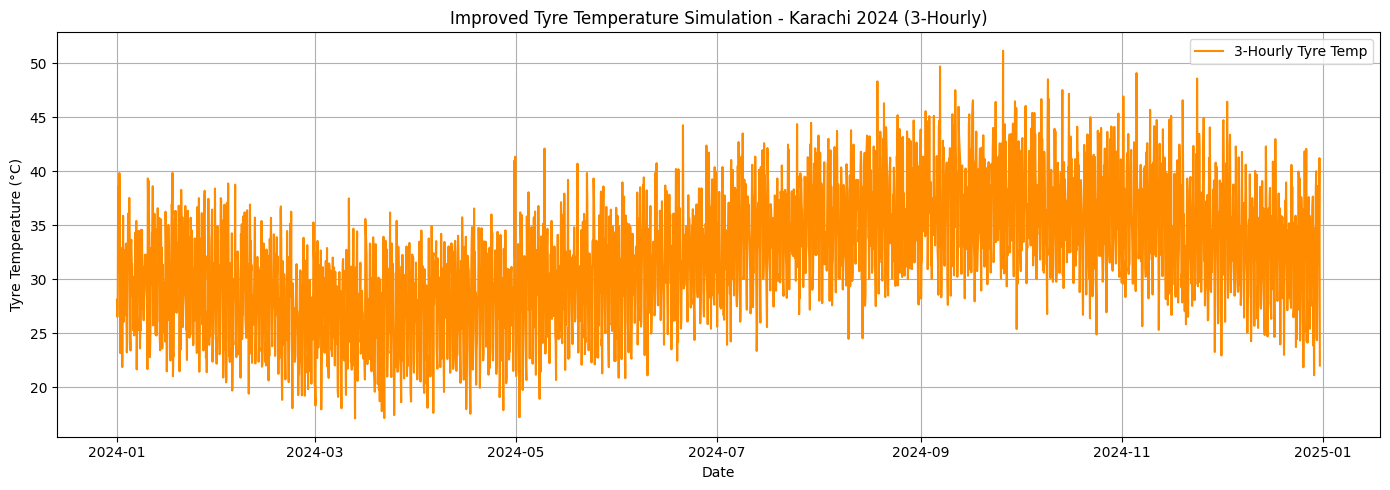

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Configuration ---
np.random.seed(42)
START_DATE = '2024-01-01'
END_DATE   = '2024-12-31'

# Parameters
AMBIENT_INFLUENCE = 0.85           # Stronger ambient influence
DRIVING_HEAT_MEAN_DAY = 10.0       # Avg gain due to driving in daytime
DRIVING_HEAT_MEAN_NIGHT = 3.0      # Avg gain during night
DRIVING_HEAT_STD = 3.0             # More variability
MAX_TYRE_TEMP = 75.0
MIN_TYRE_TEMP = 10.0

# --- Generate date range (3-hourly) ---
dates = pd.date_range(start=START_DATE, end=END_DATE, freq='3H')
n_intervals = len(dates)

# --- Karachi ambient temperature model ---
def karachi_temp_model(day_of_year):
    return 29 + 6 * np.sin(2 * np.pi * (day_of_year - 172) / 365)

ambient_temp = []
for current_date in dates:
    base_temp = karachi_temp_model(current_date.day_of_year)
    noise = np.random.normal(0, 1.5)
    ambient_temp.append(base_temp + noise)
ambient_temp = np.array(ambient_temp)

# --- Simulate Tyre Temperature ---
tyre_temp = np.zeros(n_intervals)

for i in range(n_intervals):
    ambient = ambient_temp[i]
    hour = dates[i].hour

    if 7 <= hour <= 21:
        driving_heat = np.random.normal(DRIVING_HEAT_MEAN_DAY, DRIVING_HEAT_STD)
    else:
        driving_heat = np.random.normal(DRIVING_HEAT_MEAN_NIGHT, DRIVING_HEAT_STD / 2)

    temp = (AMBIENT_INFLUENCE * ambient) + driving_heat + np.random.normal(0, 1.5)
    tyre_temp[i] = temp

# Clip values
tyre_temp = np.clip(tyre_temp, MIN_TYRE_TEMP, MAX_TYRE_TEMP)

# Create DataFrame
df_temp = pd.DataFrame({
    'Date': dates,
    'Tyre_Temperature_C': tyre_temp
})

# Plot
plt.figure(figsize=(14, 5))
plt.plot(df_temp['Date'], df_temp['Tyre_Temperature_C'], label='3-Hourly Tyre Temp', color='darkorange')
plt.title('Improved Tyre Temperature Simulation - Karachi 2024 (3-Hourly)')
plt.xlabel('Date')
plt.ylabel('Tyre Temperature (°C)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
df_temp.to_csv('tyre_temp_2024.csv', index=False)